# Fase 4 — Feature Engineering

## Objetivo
Transformar los precios crudos en un conjunto de variables (features) que capturen el estado del mercado: tendencia, momentum, volatilidad y sobrecompra/sobreventa. Estas features serán el input de los modelos predictivos (Fase 5) y del agente RL (Fase 6).

## Regla de oro: Cero Look-Ahead
Un feature en el día `t` **solo puede usar información disponible hasta el día `t`**. Si usamos datos del futuro (ej. calcular una media móvil centrada), los modelos aprenderán a hacer trampas y el backtest será una ilusión.

## Estructura
- **§1** Construcción de features (RSI, MACD, Bollinger, Momentum).
- **§2** Validación matemática (Anti-Look-Ahead).
- **§3** Inspección visual de los indicadores.
- **§4** Volatilidad y regímenes.
- **§5** Multicolinealidad (¿tenemos features redundantes?).
- **§6** Guardado del dataset final.

In [1]:
import sys
sys.path.append("../src")

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from features import build_features, add_features, _rsi_wilder, FEATURE_COLS

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)

DATA_PATH = Path("../data/processed/dataset_eda.csv")
df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
TICKERS = ["GLD", "QQQ", "SPY", "TLT"]

print(f"Dataset base: {df.shape}")

Dataset base: (11060, 12)


## §1 Construcción de features

Implementamos los indicadores técnicos clásicos, prestando atención a los detalles matemáticos que suelen ignorarse en implementaciones básicas:
- **RSI**: Usamos el suavizado de Wilder (EMA con α=1/14) en lugar de una media móvil simple, que es la definición original.
- **MACD**: Normalizamos el MACD por el precio del activo. Sin esto, un MACD de 2 dólares en SPY no es comparable con uno de 2 dólares en GLD.
- **Bollinger**: Calculamos el `%B` (posición relativa dentro de las bandas) y el `bandwidth` (ancho de las bandas).
- **Rezagos y Momentum**: Lags de retornos (1, 2, 3, 5, 10, 20 días) y retornos acumulados (5, 10, 20 días).
- **Volumen y Volatilidad**: Z-score del volumen, regímenes de volatilidad y distancia a la media de 200 días.

In [3]:
print("Construyendo features...")
df_feat = build_features(df, drop_na=True)

print(f"Shape original: {df.shape}")
print(f"Shape con features (sin NaNs): {df_feat.shape}")
print(f"Número de features generadas: {len(FEATURE_COLS)}")

Construyendo features...
[features] Filas antes: 11060, despues (sin NaN): 10264
Shape original: (11060, 12)
Shape con features (sin NaNs): (10264, 32)
Número de features generadas: 22


## §2 Validación matemática: Anti-Look-Ahead

Para demostrar que nuestro pipeline no tiene fuga de información (look-ahead bias), realizamos un test empírico:
1. Elegimos una fecha `t` en el pasado.
2. Recalculamos el RSI usando **solo los datos hasta `t`**.
3. Comparamos ese valor con el RSI que el pipeline calculó en la misma fecha.

Si la diferencia es 0.0, el cálculo es estrictamente causal.

In [4]:
# Test manual sobre una fecha arbitraria
ticker = "SPY"
# Usamos el dataset sin drop_na para no perder índices originales
df_full = add_features(df)
g_full = df_full[df_full["Ticker"] == ticker].sort_values("Date").reset_index(drop=True)

idx = 500  # Fila arbitraria lejana en el pasado
target_date = g_full.loc[idx, "Date"]

# 1. Cálculo manual usando SOLO datos hasta la fecha objetivo
sub = df[df["Ticker"] == ticker].sort_values("Date").reset_index(drop=True)
sub = sub[sub["Date"] <= target_date]
rsi_manual = _rsi_wilder(sub["Adj_Close"], 14).iloc[-1]

# 2. Cálculo del pipeline en la misma fecha
rsi_pipeline = g_full.loc[idx, "rsi_14"]

print(f"Ticker:       {ticker}")
print(f"Fecha:        {target_date.date()}")
print(f"RSI manual:   {rsi_manual:.6f}")
print(f"RSI pipeline: {rsi_pipeline:.6f}")
print(f"Diferencia:   {abs(rsi_manual - rsi_pipeline):.2e}")

assert abs(rsi_manual - rsi_pipeline) < 1e-8, "¡Look-ahead detectado!"
print("\nOK: Sin look-ahead. El feature en t solo usa datos hasta t.")

Ticker:       SPY
Fecha:        2016-12-27
RSI manual:   68.086610
RSI pipeline: 68.086610
Diferencia:   0.00e+00

OK: Sin look-ahead. El feature en t solo usa datos hasta t.


## §3 Inspección visual

Revisamos que los indicadores se comportan como esperamos:
- El **RSI** oscila entre 0 y 100. Valores > 70 indican sobrecompra, < 30 sobreventa.
- El **MACD histograma** cruza por cero en los cambios de tendencia.
- Las **Bandas de Bollinger (%B)** tocan 0 (banda inferior) y 1 (banda superior) en extremos.

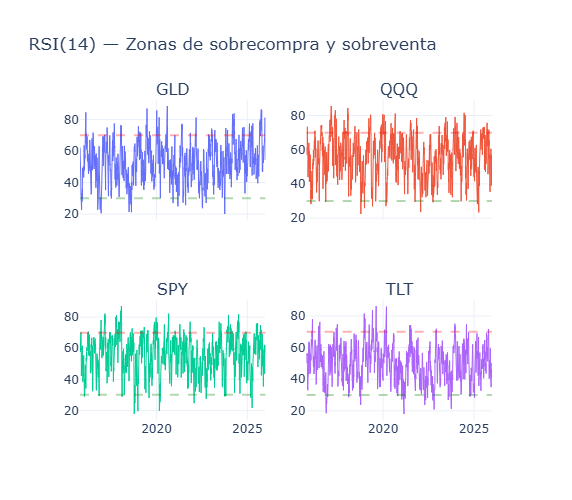

In [5]:
fig = make_subplots(rows=2, cols=2, subplot_titles=TICKERS, shared_xaxes=True)
for i, t in enumerate(TICKERS):
    sub = df_feat[df_feat["Ticker"] == t]
    r, c = divmod(i, 2)
    fig.add_trace(go.Scatter(x=sub["Date"], y=sub["rsi_14"], name=t, line=dict(width=1)), row=r+1, col=c+1)
    fig.add_hline(y=70, line_dash="dash", line_color="red", opacity=0.3, row=r+1, col=c+1)
    fig.add_hline(y=30, line_dash="dash", line_color="green", opacity=0.3, row=r+1, col=c+1)
fig.update_layout(title="RSI(14) — Zonas de sobrecompra y sobreventa", template="plotly_white", height=500, showlegend=False)
fig.show()

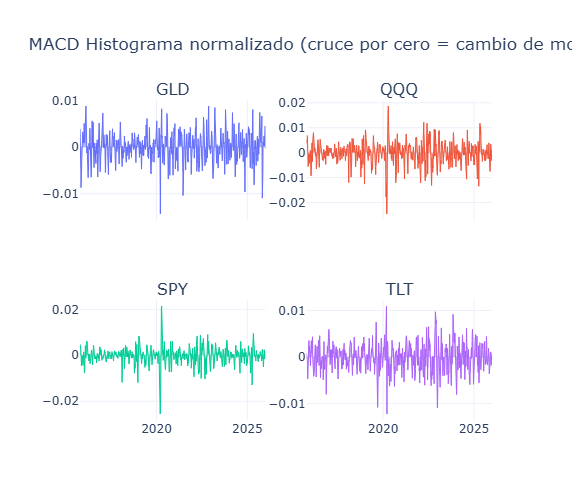

In [6]:
fig = make_subplots(rows=2, cols=2, subplot_titles=TICKERS, shared_xaxes=True)
for i, t in enumerate(TICKERS):
    sub = df_feat[df_feat["Ticker"] == t]
    r, c = divmod(i, 2)
    fig.add_trace(go.Scatter(x=sub["Date"], y=sub["macd_hist_norm"], name=t, line=dict(width=1), fill="tozeroy"), row=r+1, col=c+1)
fig.update_layout(title="MACD Histograma normalizado (cruce por cero = cambio de momentum)", template="plotly_white", height=500, showlegend=False)
fig.show()

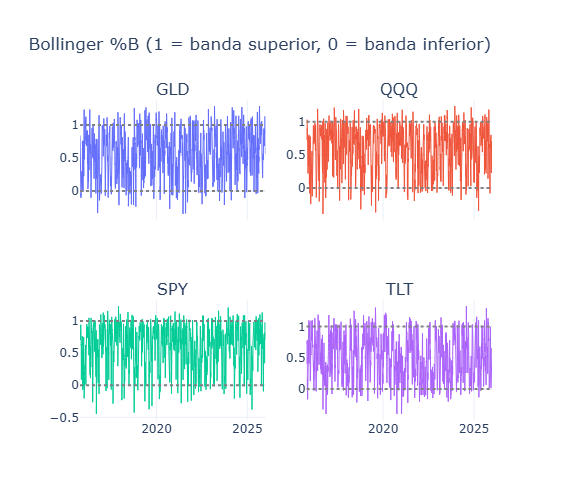

In [7]:
fig = make_subplots(rows=2, cols=2, subplot_titles=TICKERS, shared_xaxes=True)
for i, t in enumerate(TICKERS):
    sub = df_feat[df_feat["Ticker"] == t]
    r, c = divmod(i, 2)
    fig.add_trace(go.Scatter(x=sub["Date"], y=sub["bb_pct_b"], name=t, line=dict(width=1)), row=r+1, col=c+1)
    fig.add_hline(y=1, line_dash="dot", line_color="gray", row=r+1, col=c+1)
    fig.add_hline(y=0, line_dash="dot", line_color="gray", row=r+1, col=c+1)
fig.update_layout(title="Bollinger %B (1 = banda superior, 0 = banda inferior)", template="plotly_white", height=500, showlegend=False)
fig.show()

## §4 Volatilidad y regímenes

La volatilidad no es constante (clustering). Creamos un feature binario `vol_regime_high` que marca si la volatilidad actual está por encima de su percentil 70 histórico. Esto será fundamental para que el agente RL aprenda a "no operar en días de pánico".

In [ ]:
fig = make_subplots(rows=2, cols=2, subplot_titles=TICKERS, shared_xaxes=True)
for i, t in enumerate(TICKERS):
    sub = df_feat[df_feat["Ticker"] == t]
    r, c = divmod(i, 2)
    # Pintar de fondo los dias de alta volatilidad
    high_vol_dates = sub[sub["vol_regime_high"] == 1]["Date"]
    fig.add_trace(go.Scatter(x=sub["Date"], y=sub["vol_63d"], name=t, line=dict(width=1)), row=r+1, col=c+1)
    for d in high_vol_dates:
        fig.add_vline(x=d, line_width=1, line_color="red", opacity=0.05, row=r+1, col=c+1)
fig.update_layout(title="Volatilidad rolling 63d — Zonas rojas = régimen de alta volatilidad", template="plotly_white", height=500, showlegend=False)
fig.show()

## §5 Multicolinealidad

Antes de pasar a los modelos lineales (Fase 5), miramos la correlación entre features. Si dos features miden lo mismo (r > 0.9), los modelos lineales sufrirán de varianza inflada y pesos inestables.

*(Nota: esto se abordó en detalle en la Fase 5, reduciendo el set a 9 features para los modelos lineales, mientras que el RL usa las 22).*

In [ ]:
corr = df_feat[FEATURE_COLS].corr()
fig = px.imshow(
    corr, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
    title="Correlación entre features (multicolinealidad)",
)
fig.update_layout(template="plotly_white", height=700, width=800)
fig.show()

## §6 Guardado del dataset final

Guardamos el dataset con las 22 features listo para alimentar a los modelos predictivos y al agente RL.

In [ ]:
from pathlib import Path
Path("../data/processed").mkdir(parents=True, exist_ok=True)
out_path = "../data/processed/features.csv"
df_feat.to_csv(out_path, index=False)
print(f"Guardado: {out_path} ({df_feat.shape[0]} filas, {df_feat.shape[1]} columnas)")

print("\n¡Feature Engineering completado!")
print("El dataset 'features.csv' está listo para la Fase 5 (Modelos Predictivos) y Fase 6 (RL).")